# Brazil wildfire EDA

A first look at the [Brazil Wildfire Geospatial Dataset](https://huggingface.co/datasets/mateus-pcosta/brazil-wildfire-geospatial-dataset). I want to understand the data before trying to predict fire intensity.

The main questions are:
* When and where are hotspots detected?
* Are there missing values or other data issues?
* What does fire radiative power (FRP) look like?
* How does FRP vary across biomes and weather conditions?

One row is a satellite hotspot detection, not necessarily a separate wildfire. FRP measures radiative power in MW, not burned area or ecological damage.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from huggingface_hub import hf_hub_download
from IPython.display import display
from tqdm.auto import tqdm

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

years = list(range(2018, 2026))  # Change to [2023] for a smaller first run.
sample_size = 50_000
seed = 42
dataset = "mateus-pcosta/brazil-wildfire-geospatial-dataset"
revision = "23181de1a54d81e8044aa7d69fc5597ae96e7a5c"

# VS Code may start the kernel in the project folder or the eda folder.
root = Path.cwd()
if root.name == "eda":
    root = root.parent
data_dir = root / "data" / "raw"

## 1. Load the hotspot data

I am using the enriched hotspot table (`focos_analise`), not the much larger daily weather grid. The eight files are about 145 MB to download. Files are cached locally, and the revision above keeps the dataset version fixed.

I keep the columns used below and leave out extra administrative IDs. Pandas loads these rows into memory, so the full run needs more RAM than the old script. A single year is an option on a smaller machine.

In [2]:
columns = [
    "foco_id", "data_pas", "data_hora_gmt", "ano", "mes",
    "latitude", "longitude", "bioma", "estado", "satelite",
    "frp", "precipitacao", "numero_dias_sem_chuva", "risco_fogo",
    "vegetacao", "classe_mb", "nome_classe_mb", "altitude_m",
    "temp_c", "rh", "wind_speed", "tp_mm", "ffwi", "geometria",
]

frames = []
for year in tqdm(years, desc="Loading years"):
    path = hf_hub_download(
        repo_id=dataset, repo_type="dataset", revision=revision,
        filename=f"focos_analise/focos_enriquecido_{year}.parquet",
        local_dir=data_dir,
    )
    frames.append(pd.read_parquet(path, columns=columns))

df = pd.concat(frames, ignore_index=True)
del frames
df["data_pas"] = pd.to_datetime(df["data_pas"])
df["data_hora_gmt"] = pd.to_datetime(df["data_hora_gmt"])

# These repeated strings take less memory as categories.
for column in ["bioma", "estado", "satelite", "vegetacao", "nome_classe_mb"]:
    df[column] = df[column].astype("category")

print(f"{len(df):,} rows, {df.shape[1]} selected columns")
display(df.head())

Loading years:   0%|          | 0/8 [00:00<?, ?it/s]

1,430,756 rows, 24 selected columns


,foco_id,data_pas,data_hora_gmt,ano,mes,latitude,longitude,bioma,estado,satelite,frp,precipitacao,numero_dias_sem_chuva,risco_fogo,vegetacao,classe_mb,nome_classe_mb,altitude_m,temp_c,rh,wind_speed,tp_mm,ffwi,geometria
0,a326acb2-be55-3feb-916d-82f5881a18ca,2018-01-02,2018-01-02 17:00:00,2018,1,0.057,-51.148,Amazônia,AMAPÁ,AQUA_M-T,14.8,0.2,0.0,0.1,Savana arbórea; Caatinga fechada,15,Pastagem,31.0,27.738556,79.857872,3.088029,0.164509,0.621995,POINT (0.057 -51.148)
1,2997fa00-28eb-3761-bb8b-477190a06263,2018-01-03,2018-01-03 16:05:00,2018,1,-2.986,-41.734,Caatinga,PIAUÍ,AQUA_M-T,102.8,0.0,0.0,0.9,Floresta Ombrófila densa,3,Formação Florestal,32.0,28.529694,71.256927,4.773320,0.443459,1.371999,POINT (-2.986 -41.734)
2,29e1164b-a47e-38a8-89da-d326f5e1ce5e,2018-01-03,2018-01-03 16:05:00,2018,1,-3.021,-40.682,Caatinga,CEARÁ,AQUA_M-T,16.7,0.0,0.0,0.9,Savana arbórea; Caatinga fechada,3,Formação Florestal,30.0,28.614166,70.556534,3.455362,0.414371,1.017378,POINT (-3.021 -40.682)
3,b56d71dc-7e58-3db8-b827-9da881270bc3,2018-01-03,2018-01-03 16:05:00,2018,1,-3.112,-39.813,Caatinga,CEARÁ,AQUA_M-T,49.1,0.0,0.0,0.9,Savana; Caatinga aberta,48,Outra Lavoura Perene,32.0,27.512115,77.697731,4.380477,0.191689,0.976946,POINT (-3.112 -39.813)
4,7de73a0e-3b88-34c8-919c-c7bad06d6944,2018-01-03,2018-01-03 16:05:00,2018,1,-3.110,-39.802,Caatinga,CEARÁ,AQUA_M-T,61.9,0.0,0.0,0.9,Savana; Caatinga aberta,48,Outra Lavoura Perene,36.0,27.512115,77.697731,4.380477,0.191689,0.976946,POINT (-3.11 -39.802)


## 2. Detections over time

These counts use all loaded rows. I also check which dates have no records before comparing years.

,detections,first_date,last_date,detection_days,calendar_days
ano,,,,,
2018,120473,2018-01-01,2018-12-31,365,365
2019,183038,2019-01-01,2019-12-31,365,365
2020,205373,2020-01-01,2020-12-31,365,366
2021,165746,2021-01-01,2021-12-31,365,365
2022,184808,2022-01-01,2022-12-31,346,365
2023,175266,2023-01-01,2023-12-31,365,365
2024,266001,2024-01-01,2024-12-31,365,366
2025,130051,2025-01-01,2025-12-31,360,365


,dates_without_detections
0,2020-09-02
1,2022-02-09
2,2022-03-23
3,2022-04-01
4,2022-04-02
5,2022-04-03
6,2022-04-04
7,2022-04-05
8,2022-04-06
9,2022-04-07


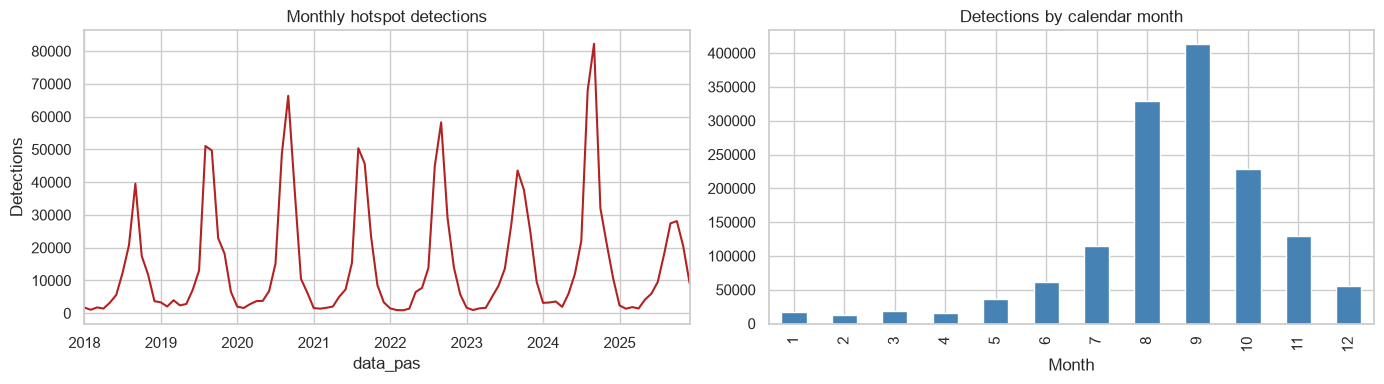

August-October share: 67.8%


In [3]:
yearly = df.groupby("ano").agg(
    detections=("foco_id", "size"),
    first_date=("data_pas", "min"),
    last_date=("data_pas", "max"),
    detection_days=("data_pas", "nunique"),
).reindex(years)
yearly["calendar_days"] = [
    len(pd.date_range(f"{year}-01-01", f"{year}-12-31")) for year in years
]
display(yearly)

calendar = pd.DatetimeIndex([])
for year in years:
    calendar = calendar.append(pd.date_range(f"{year}-01-01", f"{year}-12-31"))
missing_dates = calendar.difference(pd.DatetimeIndex(df["data_pas"].dropna().unique()))
display(pd.DataFrame({"dates_without_detections": missing_dates}))

monthly = df.groupby(df["data_pas"].dt.to_period("M")).size()
seasonality = df.groupby("mes").size().reindex(range(1, 13), fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
monthly.index = monthly.index.to_timestamp()
monthly.plot(ax=axes[0], color="firebrick", title="Monthly hotspot detections")
seasonality.plot.bar(ax=axes[1], color="steelblue", title="Detections by calendar month")
axes[0].set_ylabel("Detections")
axes[1].set_xlabel("Month")
plt.tight_layout()
plt.show()

print(f"August-October share: {seasonality.loc[8:10].sum() / len(df):.1%}")

The detections are concentrated later in the year, especially August-October. This is a pooled pattern across Brazil; each biome may have a different season.

A date without records could mean no detected hotspots or a source gap. It does not prove that there were no fires. The April 2022 gap in the full dataset needs a closer look.

## 3. Biomes and states

Which parts of the dataset have the most examples? These are detection counts, not fire risk per square kilometer.

,detections
bioma,
Amazônia,660720
Cerrado,454897
Caatinga,135827
Mata Atlântica,109774
Pantanal,63061
Pampa,6477


,detections
satelite,
AQUA_M-T,1430756


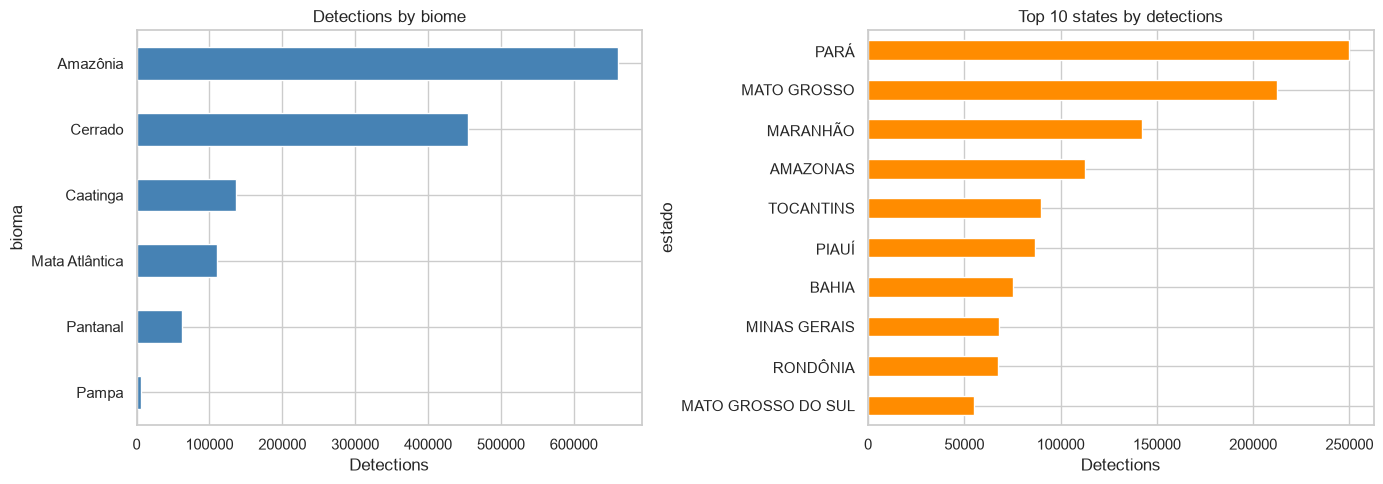

bioma,Amazônia,Caatinga,Cerrado,Mata Atlântica,Pampa,Pantanal
ano,,,,,,
2018,60305,11004,37185,9790,628,1561
2019,78933,14686,61622,16920,1185,9692
2020,91991,14096,61560,14906,1430,21390
2021,61831,17595,60152,17496,1048,7624
2022,104450,15039,53577,9531,666,1545
2023,89284,20909,48154,10083,545,6291
2024,134031,19557,77955,19837,380,14241
2025,39895,22941,54692,11211,595,717


In [4]:
biome_counts = df["bioma"].value_counts(dropna=False)
state_counts = df["estado"].value_counts(dropna=False)
display(biome_counts.to_frame("detections"))
display(df["satelite"].value_counts(dropna=False).to_frame("detections"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
biome_counts.sort_values().plot.barh(
    ax=axes[0], color="steelblue", title="Detections by biome"
)
state_counts.head(10).sort_values().plot.barh(
    ax=axes[1], color="darkorange", title="Top 10 states by detections"
)
for ax in axes:
    ax.set_xlabel("Detections")
plt.tight_layout()
plt.show()

display(pd.crosstab(df["ano"], df["bioma"]))

Amazônia and Cerrado make up most of the detections. Pampa has far fewer examples, so an overall model score could hide weak results there. I would report errors separately for each biome.

## 4. Fire intensity (FRP)

I summarize FRP using all valid target values, then use a reproducible sample for the row-level plots. `log1p` makes the long right tail easier to see. Invalid or missing FRP is excluded from these target plots, not from the original data.

count    1.428216e+06
mean     6.311508e+01
std      1.399606e+02
min      2.100000e+00
50%      2.850000e+01
90%      1.286000e+02
99%      5.857850e+02
max      9.612200e+03
Name: frp, dtype: float64

,count,median,mean,max
bioma,,,,
Amazônia,658985,27.4,62.759491,8598.4
Caatinga,135778,30.3,59.807538,8395.6
Cerrado,454326,31.1,65.476502,9612.2
Mata Atlântica,109758,17.5,40.085862,3641.8
Pampa,6465,13.0,24.558005,922.4
Pantanal,62904,47.1,101.069333,4935.9


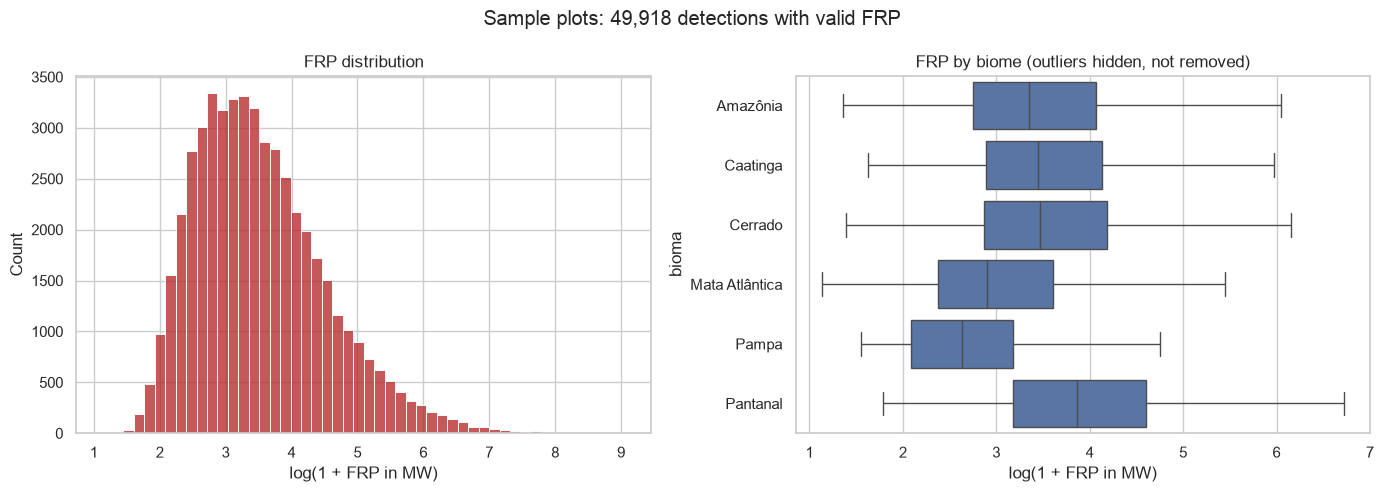

In [5]:
valid_frp = np.isfinite(df["frp"]) & df["frp"].ge(0)
display(df.loc[valid_frp, "frp"].describe(percentiles=[0.5, 0.9, 0.99]))
display(df.loc[valid_frp].groupby("bioma", observed=True)["frp"].agg(
    ["count", "median", "mean", "max"]
))

plot_df = df.sample(n=min(sample_size, len(df)), random_state=seed).copy()
frp_sample = plot_df.loc[
    np.isfinite(plot_df["frp"]) & plot_df["frp"].ge(0)
].copy()
frp_sample["log_frp"] = np.log1p(frp_sample["frp"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=frp_sample, x="log_frp", bins=50, ax=axes[0], color="firebrick")
sns.boxplot(data=frp_sample, x="log_frp", y="bioma", showfliers=False, ax=axes[1])
axes[0].set_title("FRP distribution")
axes[1].set_title("FRP by biome (outliers hidden, not removed)")
for ax in axes:
    ax.set_xlabel("log(1 + FRP in MW)")
fig.suptitle(f"Sample plots: {len(frp_sample):,} detections with valid FRP")
plt.tight_layout()
plt.show()

FRP is strongly right-skewed: the mean is much larger than the median. A log-transformed target seems like a reasonable starting point for a naive regression model. Large FRP values are not automatically errors.

The distributions also differ by biome. Pantanal has a higher median FRP in this dataset, but that does not mean its fires cause more ecological damage.

## 5. Weather and correlations

Weather columns are temperature (`temp_c`, degrees C), relative humidity (`rh`, percent), wind speed (`wind_speed`, m/s), rainfall (`tp_mm`, mm), and the Fosberg Fire Weather Index (`ffwi`).

These are weather conditions at detected hotspots, not a sample of all weather in Brazil. The plots and correlations below use the same sample as the FRP plots.

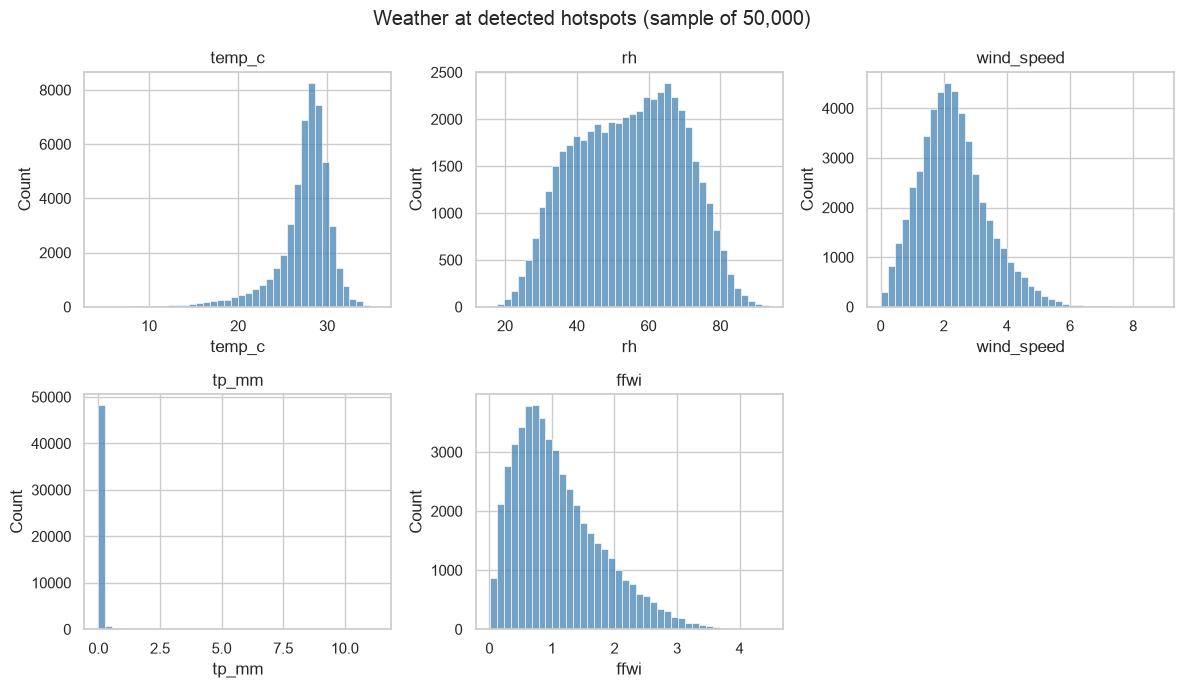

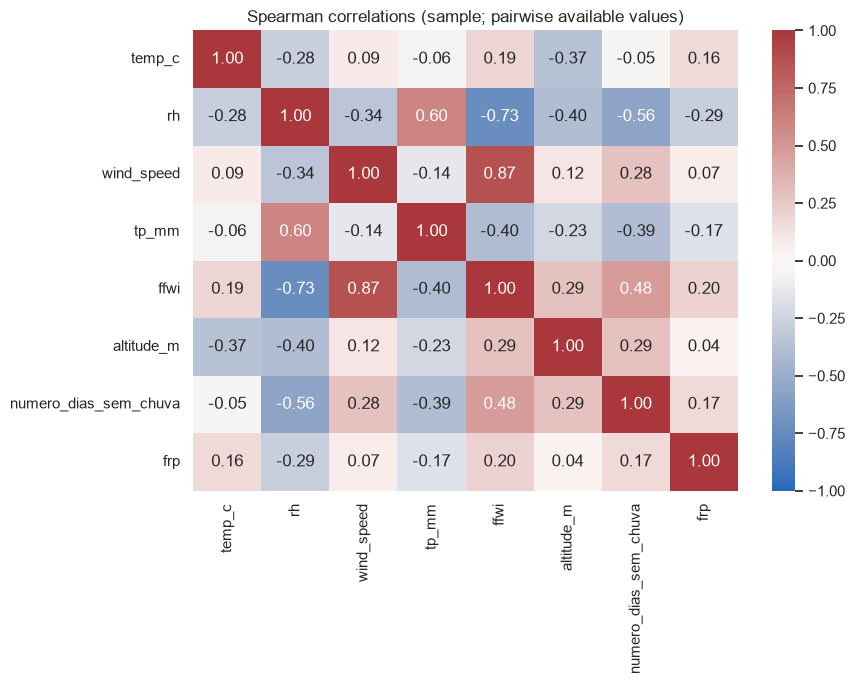

In [6]:
weather_columns = ["temp_c", "rh", "wind_speed", "tp_mm", "ffwi"]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, column in zip(axes.flat, weather_columns):
    values = plot_df[column].replace([np.inf, -np.inf], np.nan).dropna()
    sns.histplot(values, bins=40, ax=ax, color="steelblue")
    ax.set_title(column)
axes.flat[-1].set_visible(False)
fig.suptitle(f"Weather at detected hotspots (sample of {len(plot_df):,})")
plt.tight_layout()
plt.show()

correlation_columns = weather_columns + ["altitude_m", "numero_dias_sem_chuva", "frp"]
correlation_data = plot_df[correlation_columns].replace([np.inf, -np.inf], np.nan)
correlation_data.loc[correlation_data["frp"].lt(0), "frp"] = np.nan
correlations = correlation_data.corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0)
plt.title("Spearman correlations (sample; pairwise available values)")
plt.tight_layout()
plt.show()

I use Spearman correlation because the variables are skewed and I am looking for broad relationships, not only straight-line ones. Correlation does not show causation, and these associations are conditional on a hotspot being detected.

The weather index is calculated from other weather variables, so its correlations are not independent evidence. The source aggregation periods and units should be verified before making stronger claims.

## 6. Where are the sampled hotspots?

A hexbin plot keeps overlapping detections readable. This is a coordinate plot, not a map of risk or a country-boundary check.

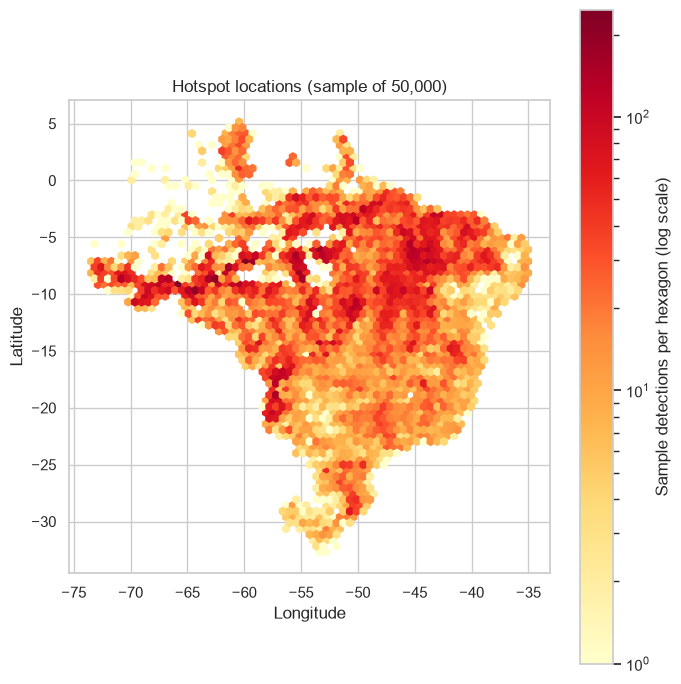

In [7]:
locations = plot_df.loc[
    plot_df["latitude"].between(-90, 90) & plot_df["longitude"].between(-180, 180)
]
plt.figure(figsize=(7, 7))
plt.hexbin(
    locations["longitude"], locations["latitude"],
    gridsize=65, mincnt=1, bins="log", cmap="YlOrRd",
)
plt.colorbar(label="Sample detections per hexagon (log scale)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(f"Hotspot locations (sample of {len(locations):,})")
plt.gca().set_aspect("equal")
plt.tight_layout()
plt.show()